# Two-stage anchor-based detector: Faster R-CNN

We train Faster R-CNN (torchvision, ResNet-50 + FPN, pretrained on COCO) on the frames prepared in the data notebook.
All experiments use the same folds the same frames and the same metric, and each experiment changes only one thing compared to the baseline.

## How to run

Run on Google Colab with a T4 GPU. The first cell mounts Google Drive and unpacks data_prepared.zip, results are saved to hw2/frcnn on the Drive.

The notebook works in two steps (see Experiments):

Step 1 compares the experiments with 5-fold cross-validation, step 2 trains the best one on fold 0 with the full protocol.

In [37]:
from google.colab import drive
drive.mount("/content/drive")
!pip install -q -U albumentations pycocotools
!unzip -q /content/drive/MyDrive/hw2/data_prepared.zip -d /content/prep
!ls /content/prep

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/prep/data_prepared/fold1.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
data_prepared  data-understanding-and-preprocessing.log


## Setup

In [39]:
import os
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"
import contextlib
import io
import json
import math
import random
import shutil
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import yaml
import albumentations as A
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.utils.data import DataLoader, Dataset
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import roi_heads as rcnn_roi_heads
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou, generalized_box_iou_loss

In [40]:
DATA_DIR = Path("/content/data")
PREP_DIR = Path("/content/prep/data_prepared")
WORK_DIR = Path("/content/drive/MyDrive/hw2/frcnn")


PREP = yaml.safe_load(open(PREP_DIR / "preprocess.yaml"))
SEED = PREP["seed"]
IMG_SIZE = PREP["img_size"]
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
IGNORE_COLOR = (114, 114, 114)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NAVY, LIGHT, MID = "#1B2A4A", "#8EC5E8", "#4A7FB5"
CLASS_COLORS = sns.color_palette("tab10", len(CLASSES))
sns.set_theme(style="whitegrid", palette=[NAVY, LIGHT, MID])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

cuda Tesla T4


## Training protocol

These settings are the same for every experiment, so that differences in the results come only from the parameter we change.

- Model: Faster R-CNN with ResNet-50 + FPN backbone, starting from COCO-pretrained weights. The last layer is replaced with a new one for our 8 classes + background.
- Input: the model resizes every frame so that its longer side is the input size, without stretching. Normalization with the ImageNet mean and std is done inside the model.
- Optimizer: SGD, learning rate 0.01, momentum 0.9, weight decay 0.0001, batch of 4 frames.
- Learning rate schedule: linear warm-up during the first 500 steps, then cosine decay to zero at the end of training.
- Mixed precision (AMP) to train faster and use less GPU memory.
- Augmentation from preprocess.yaml: horizontal flip, zoom-in crop, brightness/contrast/gamma, copy-paste of trucks and buses.
- Up to 500 detections per frame with score ≥ 0.01, because scenes have up to 180 objects and the leaderboard scores up to 500 boxes per frame
  (torchvision keeps only 100 by default).
- Evaluation on all validation frames of the fold with pycocotools: mAP (IoU 0.5–0.95), AP50 and AP for small, medium and large objects,
  with up to 500 detections per frame. Ignored regions are marked in the validation file, so detections inside them are not counted.

Two modes differ only in how much training is done:

| | cv (experiments, all folds) | full (final model, fold 0) |
|---|---|---|
| input size | 960 px | 1280 px |
| training frames | every 10th frame | every 5th frame (all prepared frames) |
| epochs | 4 | 8 |
| evaluation | after the last epoch | after every epoch |

In [41]:
MODES = {
    "cv": {"img_size": 960, "frame_step": 10, "epochs": 4, "eval_every_epoch": False},
    "full": {"img_size": IMG_SIZE, "frame_step": 5, "epochs": 8, "eval_every_epoch": True},
}
BATCH_SIZE = 4
LR = 0.01
WARMUP_STEPS = 500
NUM_WORKERS = 2
AMP = DEVICE.type == "cuda"

## Experiments

Each experiment changes one thing compared to the baseline:

- baseline: default torchvision settings, only the protocol changes above.
- more_proposals: the region proposal network passes 2× more candidate boxes to the second stage (4000 instead of 2000 in training, 2000 instead of 1000 at test time).
  Our scenes are dense, so with too few proposals some objects may never reach the second stage.
- giou_loss: the second stage learns box positions with the GIoU loss instead of Smooth L1. GIoU compares the overlap of the predicted and true box directly,
  which can matter for small boxes, where a shift of a few pixels changes the overlap a lot.

Step 1 trains every experiment in EXPERIMENTS on every fold in CV_FOLDS in the cv mode.
Step 2 trains FINAL_EXPERIMENT on FINAL_FOLD in the full mode. If FINAL_EXPERIMENT is None, the experiment with the best out-of-fold mAP from step 1 is used.

In [42]:
CONFIGS = {
    "baseline": {},
    "more_proposals": {"rpn_pre_nms_top_n_train": 4000, "rpn_post_nms_top_n_train": 4000, "rpn_pre_nms_top_n_test": 2000, "rpn_post_nms_top_n_test": 2000},
    "giou_loss": {"box_loss": "giou"},
}

EXPERIMENTS = ["baseline", "more_proposals", "giou_loss"]
CV_FOLDS = [0, 1, 2, 3, 4]
FINAL_EXPERIMENT = None
FINAL_FOLD = 0
PREVIOUS_DIR = None

## Data

The dataset reads the frames from data_prepared/images and the boxes from the COCO file of the fold. Ignored regions are already grey on the frames,
so they are not used as training targets. Labels are 1–8 (0 is background in torchvision).

In [43]:
aug = PREP["augment"]
BBOX_PARAMS = A.BboxParams(format="pascal_voc", label_fields=["labels"], min_visibility=0.3)


def make_train_transform(img_size):
    return A.Compose(
    [
        A.RandomResizedCrop(size=(img_size, img_size), scale=tuple(aug["crop"]["area"]), ratio=(0.9, 1.1), p=aug["crop"]["p"]),
        A.HorizontalFlip(p=aug["hflip"]),
        A.RandomBrightnessContrast(brightness_limit=aug["brightness_contrast"]["limit"], contrast_limit=aug["brightness_contrast"]["limit"], p=aug["brightness_contrast"]["p"]),
        A.RandomGamma(gamma_limit=tuple(aug["gamma"]["limit"]), p=aug["gamma"]["p"]),
    ],
    bbox_params=BBOX_PARAMS,
    seed=SEED,
    )


def overlaps(box, boxes):
    x1, y1, x2, y2 = box
    return any(x1 < bx2 and bx1 < x2 and y1 < by2 and by1 < y2 for bx1, by1, bx2, by2 in boxes)


class DroneDataset(Dataset):
    def __init__(self, coco_path, train, img_size=IMG_SIZE, frame_step=5):
        coco = json.loads(Path(coco_path).read_text())
        self.images = [im for im in coco["images"] if not train or (im["frame_id"] - 1) % frame_step == 0]
        anns = pd.DataFrame(coco["annotations"])
        anns = anns[anns["iscrowd"] == 0]
        self.anns = {i: g for i, g in anns.groupby("image_id")}
        self.train = train
        self.transform = make_train_transform(img_size)
        size = {im["id"]: im["width"] for im in self.images}
        rare = anns[anns["category_id"].isin([CLASSES.index(c) + 1 for c in aug["copy_paste"]["classes"]])]
        self.rare = rare.assign(file_name=rare["image_id"].map({im["id"]: im["file_name"] for im in self.images}), src_width=rare["image_id"].map(size), src_height=rare["image_id"].map({im["id"]: im["height"] for im in self.images})).dropna(subset=["file_name"])

    def __len__(self):
        return len(self.images)

    def load(self, i):
        info = self.images[i]
        img = cv2.cvtColor(cv2.imread(str(PREP_DIR / info["file_name"])), cv2.COLOR_BGR2RGB)
        g = self.anns.get(info["id"])
        if g is None:
            return info, img, np.zeros((0, 4), np.float32), np.zeros(0, np.int64)
        boxes = np.array(g["bbox"].tolist(), np.float32)
        boxes[:, 2:] += boxes[:, :2]
        boxes = boxes.clip(0, [img.shape[1], img.shape[0], img.shape[1], img.shape[0]])
        return info, img, boxes, g["category_id"].to_numpy(np.int64)

    def copy_paste(self, img, boxes, labels, n):
        H, W = img.shape[:2]
        taken = [tuple(b) for b in boxes]
        new_boxes, new_labels = [], []
        for r in self.rare.sample(min(n, len(self.rare))).itertuples():
            src = cv2.cvtColor(cv2.imread(str(PREP_DIR / r.file_name)), cv2.COLOR_BGR2RGB)
            x, y, w, h = (int(v) for v in r.bbox)
            k = W / r.src_width
            patch = cv2.resize(src[y:y + h, x:x + w], (max(1, round(w * k)), max(1, round(h * k))))
            ph, pw = patch.shape[:2]
            if pw >= W or ph >= H:
                continue
            ty = int(np.clip((y + h / 2) / r.src_height * H - ph / 2, 0, H - ph))
            tx = int(np.random.randint(0, W - pw))
            grey_share = (np.abs(img[ty:ty + ph, tx:tx + pw].astype(int) - IGNORE_COLOR).max(axis=2) <= 3).mean()
            if overlaps((tx, ty, tx + pw, ty + ph), taken) or grey_share > 0.05:
                continue
            img[ty:ty + ph, tx:tx + pw] = patch
            taken.append((tx, ty, tx + pw, ty + ph))
            new_boxes.append([tx, ty, tx + pw, ty + ph])
            new_labels.append(r.category_id)
        if new_boxes:
            boxes = np.vstack([boxes, np.array(new_boxes, np.float32)])
            labels = np.concatenate([labels, np.array(new_labels, np.int64)])
        return img, boxes, labels

    def __getitem__(self, i):
        info, img, boxes, labels = self.load(i)
        if self.train:
            if np.random.rand() < aug["copy_paste"]["p"]:
                img, boxes, labels = self.copy_paste(img, boxes, labels, aug["copy_paste"]["per_frame"])
            out = self.transform(image=img, bboxes=boxes, labels=labels)
            img, boxes, labels = out["image"], np.asarray(out["bboxes"], np.float32).reshape(-1, 4), np.asarray(out["labels"], np.int64)
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), "labels": torch.tensor(labels, dtype=torch.int64), "image_id": info["id"]}
        return torch.from_numpy(img.copy()).permute(2, 0, 1).float() / 255, target


def collate(batch):
    return tuple(zip(*batch))


def seed_worker(worker_id):
    seed = SEED + worker_id
    np.random.seed(seed)
    random.seed(seed)
    torch.utils.data.get_worker_info().dataset.transform.set_random_seed(seed)


def make_loaders(fold, mode):
    m = MODES[mode]
    train_ds = DroneDataset(PREP_DIR / "coco" / f"fold{fold}_train.json", train=True, img_size=m["img_size"], frame_step=m["frame_step"])
    val_ds = DroneDataset(PREP_DIR / "coco" / f"fold{fold}_val.json", train=False)
    g = torch.Generator().manual_seed(SEED)
    train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g, drop_last=True)
    val_dl = DataLoader(val_ds, BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=NUM_WORKERS)
    return train_ds, val_ds, train_dl, val_dl

## Model

The GIoU loss is added by replacing the box loss of the second stage. The predicted and the true box are decoded from their offsets
relative to the same proposal, and the GIoU loss is computed between them. The classification loss stays the same.

In [44]:
ORIGINAL_BOX_LOSS = rcnn_roi_heads.fastrcnn_loss
BOX_WEIGHTS = (10.0, 10.0, 5.0, 5.0)


def decode_relative(deltas):
    dx, dy, dw, dh = (deltas[:, i] / w for i, w in enumerate(BOX_WEIGHTS))
    w, h = dw.clamp(max=math.log(1000 / 16)).exp(), dh.clamp(max=math.log(1000 / 16)).exp()
    return torch.stack([dx - w / 2, dy - h / 2, dx + w / 2, dy + h / 2], dim=1)


def fastrcnn_loss_giou(class_logits, box_regression, labels, regression_targets):
    labels = torch.cat(labels, dim=0)
    regression_targets = torch.cat(regression_targets, dim=0)
    classification_loss = F.cross_entropy(class_logits, labels)
    pos = torch.where(labels > 0)[0]
    box_regression = box_regression.reshape(class_logits.shape[0], -1, 4)
    pred = decode_relative(box_regression[pos, labels[pos]].float())
    target = decode_relative(regression_targets[pos].float())
    box_loss = generalized_box_iou_loss(pred, target, reduction="sum") / labels.numel()
    return classification_loss, box_loss


def build_model(name, img_size):
    cfg = CONFIGS[name]
    rpn_kwargs = {k: v for k, v in cfg.items() if k.startswith("rpn_")}
    model = fasterrcnn_resnet50_fpn(weights="DEFAULT", min_size=img_size, max_size=img_size, box_detections_per_img=500, box_score_thresh=0.01, **rpn_kwargs)
    model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
    rcnn_roi_heads.fastrcnn_loss = fastrcnn_loss_giou if cfg.get("box_loss") == "giou" else ORIGINAL_BOX_LOSS
    return model.to(DEVICE)

## Training and evaluation

In [45]:
def make_optimizer(model, steps_total):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
    warm = lambda s: (s + 1) / WARMUP_STEPS if s < WARMUP_STEPS else 0.5 * (1 + math.cos(math.pi * (s - WARMUP_STEPS) / max(1, steps_total - WARMUP_STEPS)))
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, warm)


def train_one_epoch(model, loader, optimizer, scheduler, scaler, max_steps=None):
    model.train()
    logs = []
    for step, (images, targets) in enumerate(loader):
        if max_steps and step >= max_steps:
            break
        images = [im.to(DEVICE) for im in images]
        targets = [{"boxes": t["boxes"].to(DEVICE), "labels": t["labels"].to(DEVICE)} for t in targets]
        with torch.autocast(DEVICE.type, enabled=AMP):
            losses = model(images, targets)
            loss = sum(losses.values())
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        logs.append({k: v.item() for k, v in losses.items()})
    return pd.DataFrame(logs).mean()


@torch.no_grad()
def predict(model, loader, max_batches=None):
    model.eval()
    dets = []
    for b, (images, targets) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        with torch.autocast(DEVICE.type, enabled=AMP):
            outputs = model([im.to(DEVICE) for im in images])
        for t, o in zip(targets, outputs):
            boxes = o["boxes"].float().cpu().numpy()
            boxes[:, 2:] -= boxes[:, :2]
            dets += [{"image_id": t["image_id"], "category_id": int(l), "bbox": [round(float(v), 2) for v in bb], "score": round(float(s), 4)} for bb, l, s in zip(boxes, o["labels"].tolist(), o["scores"].tolist())]
    return dets


def coco_metrics(gt_path, dets):
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(str(gt_path))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]}, None
        ev = COCOeval(gt, gt.loadRes(dets), "bbox")
        ev.params.maxDets = [1, 100, 500]
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    s = ev.stats
    return {"mAP": float(s[0]), "AP50": float(s[1]), "AP_small": float(s[3]), "AP_medium": float(s[4]), "AP_large": float(s[5])}, ev

In [46]:
RESULTS = WORK_DIR / "results.csv"


def finished(name, fold, mode):
    if not RESULTS.exists():
        return False
    r = pd.read_csv(RESULTS)
    return ((r["experiment"] == name) & (r["fold"] == fold) & (r["mode"] == mode) & (r["epoch"] == MODES[mode]["epochs"])).any()


def run(name, fold, mode):
    set_seed(SEED)
    m = MODES[mode]
    tag = f"{name}_{mode}_fold{fold}"
    train_ds, val_ds, train_dl, val_dl = make_loaders(fold, mode)
    model = build_model(name, m["img_size"])
    optimizer, scheduler = make_optimizer(model, m["epochs"] * len(train_dl))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    gt_path = PREP_DIR / "coco" / f"fold{fold}_val.json"
    best = -1.0
    for epoch in range(1, m["epochs"] + 1):
        start = time.time()
        losses = train_one_epoch(model, train_dl, optimizer, scheduler, scaler)
        if not m["eval_every_epoch"] and epoch < m["epochs"]:
            print(f"{tag} epoch {epoch}: loss {losses.sum():.3f}  ({(time.time() - start) / 60:.1f} min)")
            continue
        dets = predict(model, val_dl)
        metrics, _ = coco_metrics(gt_path, dets)
        row = {"experiment": name, "mode": mode, "fold": fold, "epoch": epoch, **metrics, "loss": losses.sum(), **losses.to_dict(), "minutes": (time.time() - start) / 60}
        pd.DataFrame([row]).to_csv(RESULTS, mode="a", header=not RESULTS.exists(), index=False)
        print(f"{tag} epoch {epoch}: mAP {metrics['mAP']:.4f}  AP50 {metrics['AP50']:.4f}  AP_small {metrics['AP_small']:.4f}  ({row['minutes']:.1f} min)")
        if metrics["mAP"] > best:
            best = metrics["mAP"]
            torch.save(model.state_dict(), WORK_DIR / f"{tag}.pt")
            (WORK_DIR / f"{tag}_val_dets.json").write_text(json.dumps(dets))
    return model


def out_of_fold(name, mode, folds):
    offset, images, anns, all_dets = 0, [], [], []
    for f in folds:
        gt = json.loads((PREP_DIR / "coco" / f"fold{f}_val.json").read_text())
        d = json.loads((WORK_DIR / f"{name}_{mode}_fold{f}_val_dets.json").read_text())
        images += [{**im, "id": im["id"] + offset} for im in gt["images"]]
        anns += [{**a, "id": len(anns) + j + 1, "image_id": a["image_id"] + offset} for j, a in enumerate(gt["annotations"])]
        all_dets += [{**x, "image_id": x["image_id"] + offset} for x in d]
        offset += max(im["id"] for im in gt["images"])
    (WORK_DIR / "oof_gt.json").write_text(json.dumps({"images": images, "annotations": anns, "categories": gt["categories"]}))
    return coco_metrics(WORK_DIR / "oof_gt.json", all_dets)[0]

Results of a previous session. If PREVIOUS_DIR points to the output of an earlier run of this notebook,
its results.csv, weights and predictions are copied to WORK_DIR, and finished runs are skipped.

In [47]:
if PREVIOUS_DIR:
    for f in Path(PREVIOUS_DIR).glob("*"):
        if f.suffix in {".pt", ".json", ".csv"} and not (WORK_DIR / f.name).exists():
            shutil.copy(f, WORK_DIR / f.name)
    print(pd.read_csv(RESULTS).groupby(["experiment", "mode"])["fold"].unique() if RESULTS.exists() else "no previous results")

## Step 1: cross-validation of the experiments

In [48]:
for name in EXPERIMENTS:
    for fold in CV_FOLDS:
        if not finished(name, fold, "cv"):
            run(name, fold, "cv")

### Cross-validation results

For every experiment: mean and standard deviation of the metrics over the folds, the out-of-fold mAP (all validation predictions of all folds evaluated together),
and the difference from the baseline.

In [49]:
metric_cols = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
results = pd.read_csv(RESULTS)
cv_rows = results[(results["mode"] == "cv") & (results["epoch"] == MODES["cv"]["epochs"])].drop_duplicates(["experiment", "fold"], keep="last")
cv_mean = cv_rows.groupby("experiment")[metric_cols].agg(["mean", "std"]).round(4)
oof = pd.DataFrame({name: out_of_fold(name, "cv", sorted(g["fold"])) for name, g in cv_rows.groupby("experiment")}).T.add_prefix("OOF ")
if "baseline" in oof.index:
    oof = oof.join((oof - oof.loc["baseline"]).add_prefix("Δ "))
display(cv_mean)
oof.round(4)

mAP            AP50         AP_small         AP_medium  \
                  mean     std    mean     std     mean     std      mean   
experiment                                                                  
baseline        0.1832  0.0106  0.3755  0.0269   0.0591  0.0183    0.1712   
giou_loss       0.1749  0.0074  0.3655  0.0180   0.0552  0.0186    0.1623   
more_proposals  0.1860  0.0079  0.3867  0.0238   0.0634  0.0209    0.1763   

                       AP_large          
                   std     mean     std  
experiment                               
baseline        0.0200   0.4145  0.0286  
giou_loss       0.0186   0.4011  0.0292  
more_proposals  0.0225   0.4138  0.0268

,OOF mAP,OOF AP50,OOF AP_small,OOF AP_medium,OOF AP_large,Δ OOF mAP,Δ OOF AP50,Δ OOF AP_small,Δ OOF AP_medium,Δ OOF AP_large
baseline,0.1782,0.3679,0.0481,0.1651,0.3979,0.0000,0.0000,0.0000,0.0000,0.0000
giou_loss,0.1700,0.3580,0.0443,0.1569,0.3782,-0.0083,-0.0099,-0.0038,-0.0082,-0.0197
more_proposals,0.1811,0.3789,0.0513,0.1722,0.3956,0.0029,0.0110,0.0032,0.0071,-0.0023


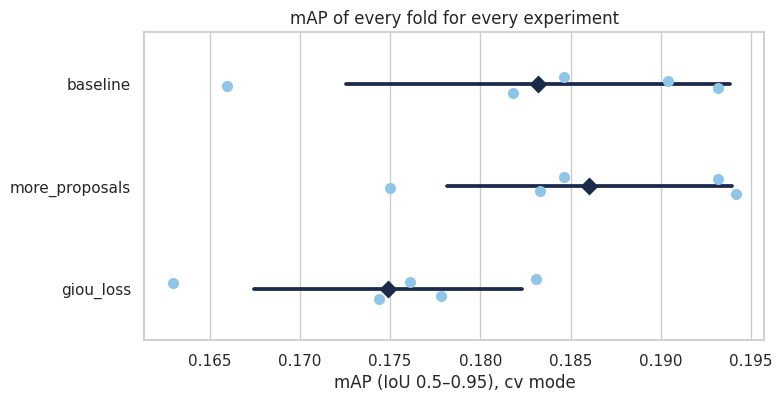

In [50]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(cv_rows, x="mAP", y="experiment", order=EXPERIMENTS, color=LIGHT, size=8, jitter=0.1, ax=ax)
sns.pointplot(cv_rows, x="mAP", y="experiment", order=EXPERIMENTS, color=NAVY, linestyle="none", errorbar="sd", markers="D", ax=ax)
ax.set(xlabel="mAP (IoU 0.5–0.95), cv mode", ylabel="", title="mAP of every fold for every experiment")
plt.show()

more_proposals has the best mean mAP, then baseline and giou_loss. But it's only a small improvement.

## Step 2: the final model in the full mode

In [51]:
final_name = FINAL_EXPERIMENT or oof["OOF mAP"].idxmax()
print("final experiment:", final_name)
if not finished(final_name, FINAL_FOLD, "full"):
    run(final_name, FINAL_FOLD, "full")

final experiment: more_proposals


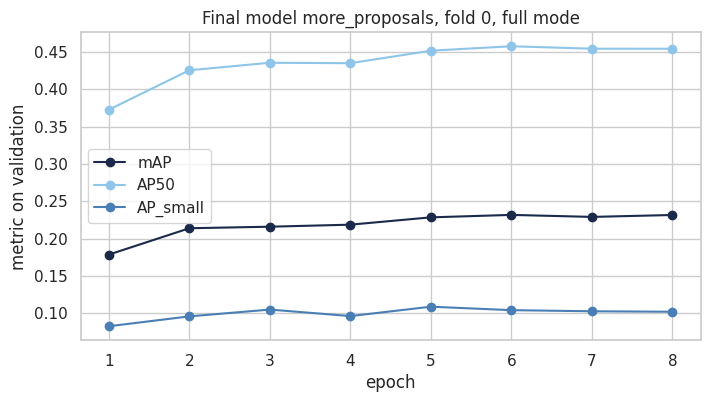

,epoch,mAP,AP50,AP_small,AP_medium,AP_large
20,6,0.2317,0.4577,0.1041,0.209,0.4792


In [52]:
results = pd.read_csv(RESULTS)
full_rows = results[(results["mode"] == "full") & (results["experiment"] == final_name) & (results["fold"] == FINAL_FOLD)].drop_duplicates("epoch", keep="last")

fig, ax = plt.subplots(figsize=(8, 4))
full_rows.plot(x="epoch", y=["mAP", "AP50", "AP_small"], marker="o", color=[NAVY, LIGHT, MID], ax=ax)
ax.set(ylabel="metric on validation", title=f"Final model {final_name}, fold {FINAL_FOLD}, full mode")
plt.show()
full_rows.loc[[full_rows["mAP"].idxmax()], ["epoch"] + metric_cols].round(4)

mAP grows fast in the first two epochs and then slowly, the best is 0.2317 at epoch 6 (AP50 0.4577, AP_small 0.1041). Epochs 7 and 8 didn't improve it.

## Analysis of the final model

In [53]:
ANALYSE = final_name
fold = FINAL_FOLD
tag = f"{ANALYSE}_full_fold{fold}"
_, val_ds, _, val_dl = make_loaders(fold, "full")
model = build_model(ANALYSE, MODES["full"]["img_size"])
model.load_state_dict(torch.load(WORK_DIR / f"{tag}.pt", map_location=DEVICE))
model.eval()
gt_path = PREP_DIR / "coco" / f"fold{fold}_val.json"
dets = json.loads((WORK_DIR / f"{tag}_val_dets.json").read_text())
metrics, ev = coco_metrics(gt_path, dets)
print(ANALYSE, {k: round(v, 4) for k, v in metrics.items()})

more_proposals {'mAP': 0.2317, 'AP50': 0.4577, 'AP_small': 0.1041, 'AP_medium': 0.209, 'AP_large': 0.4792}


### Inference speed

Time per frame on the validation set with batch size 1, after a short warm-up. It includes resizing inside the model and post-processing, but not reading the image from disk.

In [55]:
@torch.no_grad()
def inference_speed(model, dataset, n=100):
    model.eval()
    images = [dataset[i][0].to(DEVICE) for i in range(min(n + 10, len(dataset)))]
    for im in images[:10]:
        model([im])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for im in images[10:]:
        with torch.autocast(DEVICE.type, enabled=AMP):
            model([im])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    ms = (time.time() - start) / len(images[10:]) * 1000
    return {"ms per frame": round(ms, 1), "FPS": round(1000 / ms, 1), "GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"}


inference_speed(model, val_ds)

{'ms per frame': 87.0, 'FPS': 11.5, 'GPU': 'Tesla T4'}

### Per-class AP

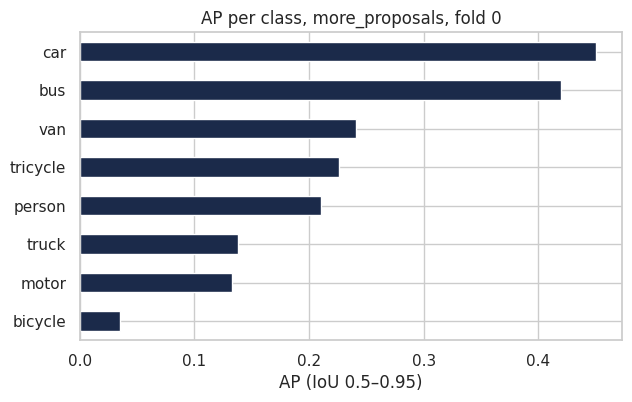

,AP
bicycle,0.0352
motor,0.1327
truck,0.1378
person,0.2109
tricycle,0.2264
van,0.2412
bus,0.4198
car,0.4504


In [56]:
precision = ev.eval["precision"][:, :, :, 0, -1]
per_class = pd.Series({c: precision[:, :, k][precision[:, :, k] > -1].mean() if (precision[:, :, k] > -1).any() else np.nan for k, c in enumerate(CLASSES)}, name="AP").sort_values()

ax = per_class.plot.barh(color=NAVY, figsize=(7, 4))
ax.set(xlabel="AP (IoU 0.5–0.95)", title=f"AP per class, {ANALYSE}, fold {fold}")
plt.show()
per_class.round(4)

This plot shows the AP of every class on the validation frames of the fold, from the worst to the best class. 

AP goes from 0.035 for bicycle to 0.450 for car. Bus has 0.420 even though it is under 1 % of objects, so being rare is not the main problem, small size is.

### What the region proposal stage and the second stage contribute

Faster R-CNN works in two steps. The region proposal network (RPN) looks at the whole frame and suggests candidate boxes that may contain an object,
without saying which class. The second stage (RoI head) takes each candidate, decides its class or rejects it as background, and corrects the box position.

To see what each step adds, we measure recall on validation frames: the share of true objects that have a box with IoU ≥ 0.5 among
(1) all RPN proposals and (2) the final detections with score ≥ 0.3 (class not checked). Objects missed by the RPN can never be found by the second stage.

In [57]:
@torch.no_grad()
def stage_recall(model, dataset, n_images=300, iou=0.5, score=0.3):
    model.eval()
    rows, n_props, n_dets = [], [], []
    for i in range(min(n_images, len(dataset))):
        img, tgt = dataset[i]
        if len(tgt["boxes"]) == 0:
            continue
        images, targets = model.transform([img.to(DEVICE)], [{"boxes": tgt["boxes"].to(DEVICE), "labels": tgt["labels"].to(DEVICE)}])
        features = model.backbone(images.tensors)
        proposals, _ = model.rpn(images, features)
        detections, _ = model.roi_heads(features, proposals, images.image_sizes)
        gt = targets[0]["boxes"]
        kept = detections[0]["boxes"][detections[0]["scores"] >= score]
        prop_hit = box_iou(gt, proposals[0]).max(1).values >= iou
        det_hit = box_iou(gt, kept).max(1).values >= iou if len(kept) else torch.zeros(len(gt), dtype=torch.bool, device=DEVICE)
        size = ((gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])).sqrt()
        rows.append(pd.DataFrame({"size": size.cpu().numpy(), "RPN proposals": prop_hit.cpu().numpy(), "final detections": det_hit.cpu().numpy()}))
        n_props.append(len(proposals[0]))
        n_dets.append(len(kept))
    df = pd.concat(rows)
    df["object size"] = pd.cut(df["size"], [0, 32, 96, np.inf], labels=["small", "medium", "large"])
    table = df.groupby("object size", observed=True)[["RPN proposals", "final detections"]].mean()
    table.loc["all"] = df[["RPN proposals", "final detections"]].mean()
    print(f"mean boxes per frame: {np.mean(n_props):.0f} proposals → {np.mean(n_dets):.0f} detections")
    return table.round(3)


recall_table = stage_recall(model, val_ds)
recall_table

mean boxes per frame: 2000 proposals → 22 detections


,RPN proposals,final detections
object size,,
small,0.819,0.667
medium,0.960,0.866
large,1.000,0.962
all,0.889,0.766


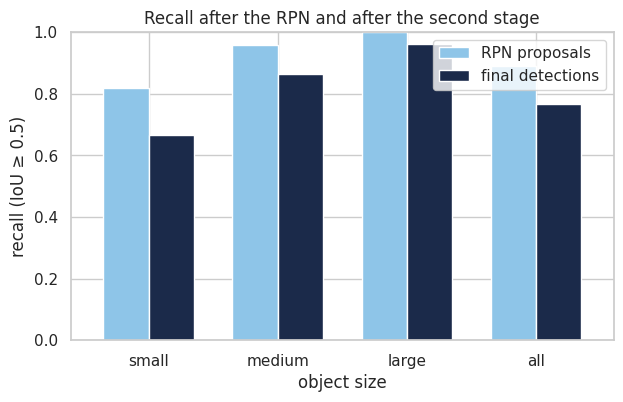

In [58]:
ax = recall_table.plot.bar(color=[LIGHT, NAVY], figsize=(7, 4), rot=0, width=0.7)
ax.set(ylabel="recall (IoU ≥ 0.5)", ylim=(0, 1), title="Recall after the RPN and after the second stage")
plt.show()

This plot shows for each object size, the share of true objects covered by at least one RPN proposal (light) and by at least one final detection (navy). The gap between the bars is what is lost in the second stage.

Proposals cover 89 % of objects and final detections 77 %. For small objects it drops from 82 % to 67 %, while large ones stay almost at 100 %. So small objects are lost already in the RPN and even more in the second stage.

The RPN does the searching: with about 2000 proposals per frame it already reaches 89 % of all objects and almost all medium and large ones, but only 82 % of small ones, so some small objects are lost before the second stage even sees them. The second stage turns these 2000 boxes into about 22 detections per frame by throwing away background and duplicates and giving each box a class, which is what makes the output usable, but it also drops part of the correct proposals, most of all for small objects, where recall goes from 82 % to 67 %. So for small objects both stages are a bottleneck, which also fits with more_proposals giving a small gain on small objects.

### Failure cases

We match the final detections with score ≥ 0.3 to the true boxes (IoU ≥ 0.5). Every true object is then one of:
found (right class), wrong class (box found, class wrong) or missed (no box). Detections that match nothing are false positives.

In [59]:
gt_json = json.loads(gt_path.read_text())
gt_df = pd.DataFrame([a for a in gt_json["annotations"] if not a["iscrowd"]])
img_info = pd.DataFrame(gt_json["images"]).set_index("id")
det_df = pd.DataFrame(dets)
det_df = det_df[det_df["score"] >= 0.3]
xyxy = lambda b: torch.tensor([[x, y, x + w, y + h] for x, y, w, h in b], dtype=torch.float32).reshape(-1, 4)

rows, fp_rows = [], []
for image_id, g in gt_df.groupby("image_id"):
    d = det_df[det_df["image_id"] == image_id]
    gt_boxes, det_boxes = xyxy(g["bbox"]), xyxy(d["bbox"])
    iou = box_iou(gt_boxes, det_boxes) if len(d) else torch.zeros(len(g), 0)
    best_iou, best_j = (iou.max(1) if len(d) else (torch.zeros(len(g)), torch.zeros(len(g), dtype=torch.long)))
    pred_cls = d["category_id"].to_numpy()[best_j.numpy()] if len(d) else np.zeros(len(g), int)
    status = np.where(best_iou.numpy() < 0.5, "missed", np.where(pred_cls == g["category_id"].to_numpy(), "found", "wrong class"))
    rows.append(g.assign(status=status, pred_class=np.where(status == "missed", 0, pred_cls)))
    matched = iou.max(0).values >= 0.5 if len(g) and len(d) else torch.zeros(len(d), dtype=torch.bool)
    fp_rows.append(d[~matched.numpy()])

match = pd.concat(rows)
false_pos = pd.concat(fp_rows)
info = img_info.loc[match["image_id"]]
match["class"] = match["category_id"].map(lambda c: CLASSES[c - 1])
match["size"] = np.sqrt(match["bbox"].str[2] * match["bbox"].str[3]) * IMG_SIZE / np.maximum(info["width"], info["height"]).to_numpy()
match["object size"] = pd.cut(match["size"], [0, 16, 32, 64, np.inf], labels=["< 16 px", "16–32 px", "32–64 px", "> 64 px"])
match["position"] = pd.cut((match["bbox"].str[1] + match["bbox"].str[3] / 2) / info["height"].to_numpy(), [0, 1 / 3, 2 / 3, 1.01], labels=["top", "middle", "bottom"])
match["video"] = info["video"].to_numpy()
print(match["status"].value_counts(normalize=True).round(3).to_dict(), f"false positives: {len(false_pos)}")

{'found': 0.691, 'missed': 0.228, 'wrong class': 0.081} false positives: 16222


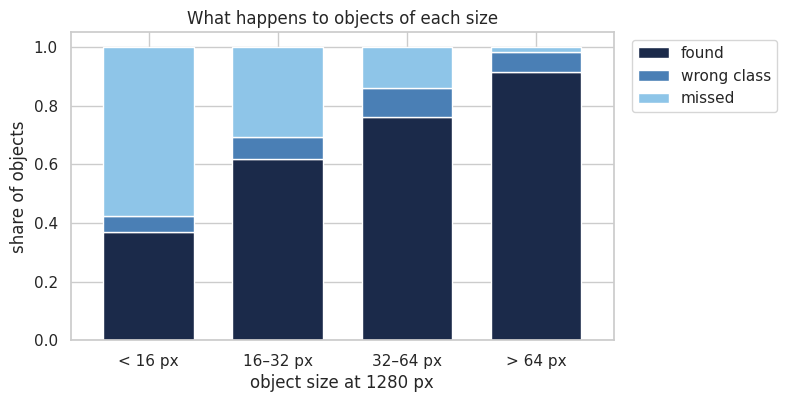

In [60]:
miss_by_size = pd.crosstab(match["object size"], match["status"], normalize="index").reindex(columns=["found", "wrong class", "missed"], fill_value=0)
ax = miss_by_size.plot.bar(stacked=True, color=[NAVY, MID, LIGHT], figsize=(7, 4), rot=0, width=0.7)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(ylabel="share of objects", xlabel="object size at 1280 px", title="What happens to objects of each size")
plt.show()

This plot shows for objects of each size (measured as if the frame were resized to 1280 px), the share that is found, found with the wrong class, or missed.

Overall 69 % of objects are found, 8 % get the wrong class and 23 % are missed. Objects under 16 px are missed in about 58 % of cases, objects over 64 px in only about 2 %.

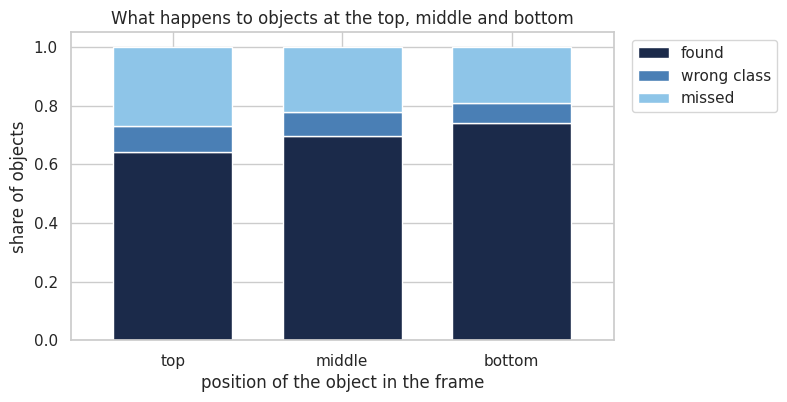

In [61]:
miss_by_pos = pd.crosstab(match["position"], match["status"], normalize="index").reindex(columns=["found", "wrong class", "missed"], fill_value=0)
ax = miss_by_pos.plot.bar(stacked=True, color=[NAVY, MID, LIGHT], figsize=(7, 4), rot=0, width=0.7)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(ylabel="share of objects", xlabel="position of the object in the frame", title="What happens to objects at the top, middle and bottom")
plt.show()

This plot shows the same split, but by where the object is in the frame. Because of the perspective, objects at the top are smaller.

Objects at the top of the frame are missed more often than at the bottom, because far objects are smaller.

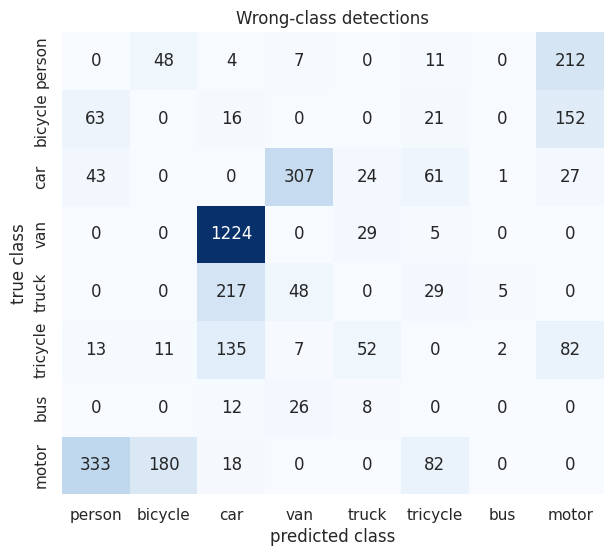

In [62]:
wrong = match[match["status"] == "wrong class"]
confusion = pd.crosstab(wrong["class"], wrong["pred_class"].map(lambda c: CLASSES[c - 1])).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="predicted class", ylabel="true class", title="Wrong-class detections")
plt.show()

This plot shows for objects found in the right place but with the wrong class, which true class (row) was predicted as which class (column).

The most common mistakes are van predicted as car (1224), motor as person (333) and car as van (307). Also truck is often predicted as car and bicycle as motor. These are the pairs with similar sizes from the data analysis.

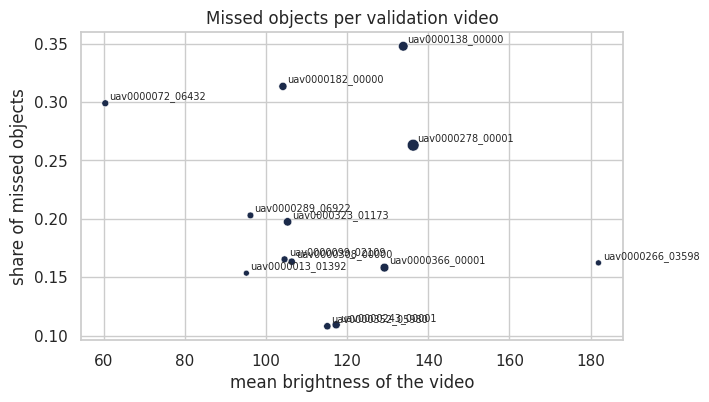

In [63]:
folds_csv = pd.read_csv(PREP_DIR / "folds.csv").drop_duplicates("video").set_index("video")
per_video = match.groupby("video").agg(missed=("status", lambda s: (s == "missed").mean()), objects=("status", "size")).join(folds_csv["brightness"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(per_video, x="brightness", y="missed", size="objects", color=NAVY, ax=ax, legend=False)
for v, r in per_video.iterrows():
    ax.annotate(v[:16], (r["brightness"], r["missed"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="mean brightness of the video", ylabel="share of missed objects", title="Missed objects per validation video")
plt.show()

Each dot is one validation video, its brightness and the share of its objects that were missed. Bigger dots have more objects.

Brightness doesn't explain the misses: the darkest video misses 30 % and the brightest only 16 %, but the worst video (35 % missed) has normal brightness. The hard videos are more likely the crowded ones with small objects.

Below are the three validation frames with the most missed objects, the most wrong-class detections and the most false positives.
Light blue: found correctly. Red: missed. Orange: wrong class (drawn at the true box). Yellow: false positive.

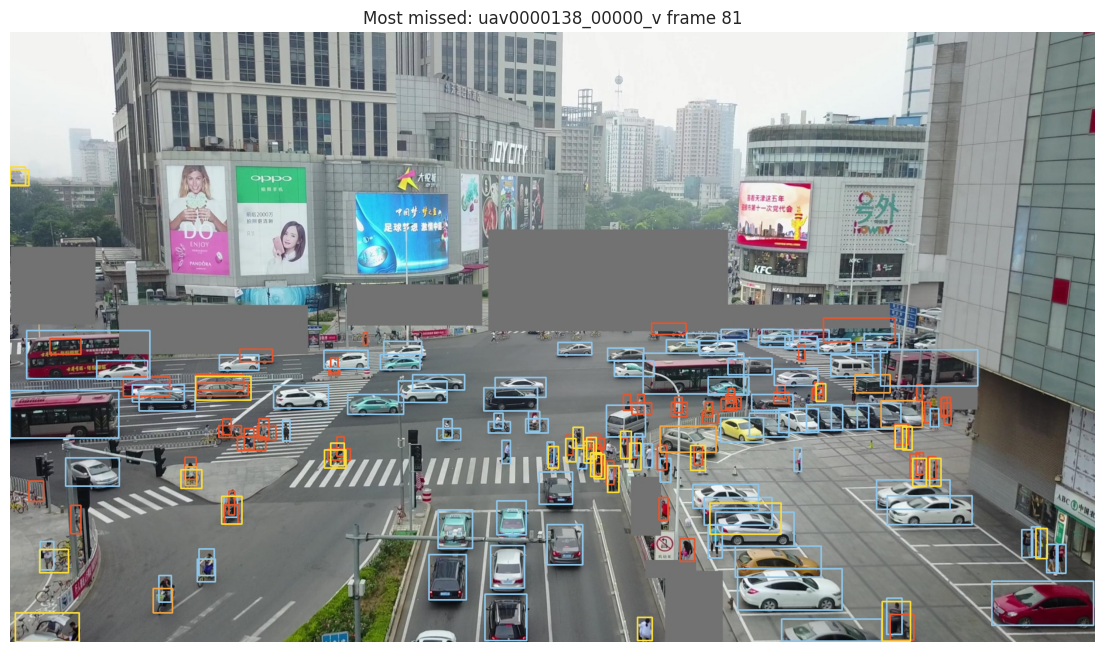

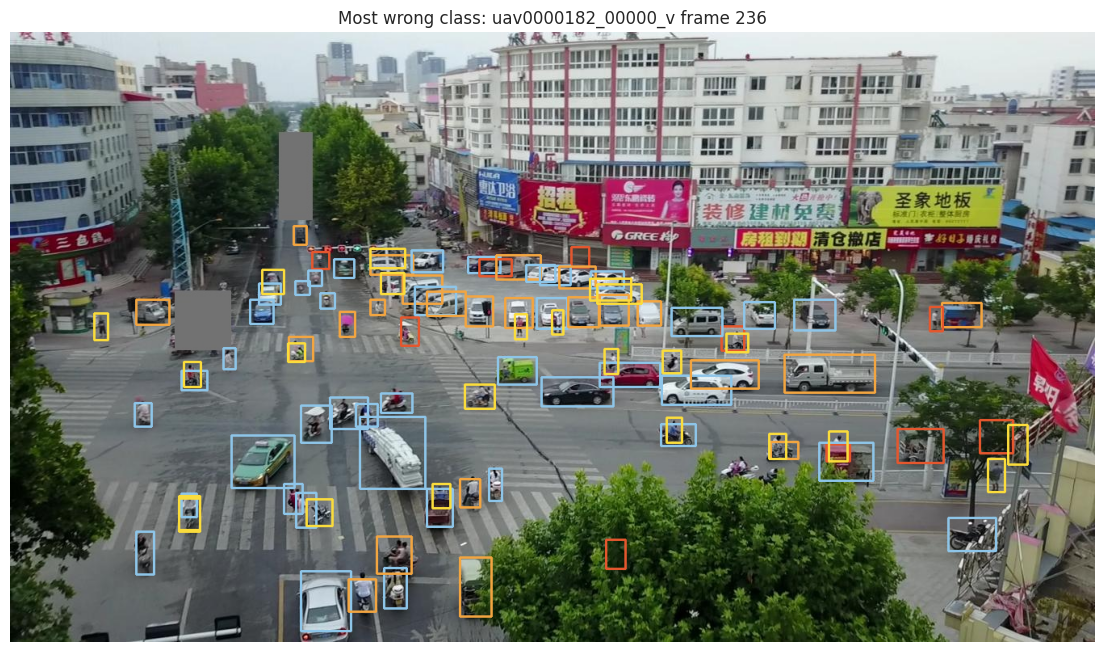

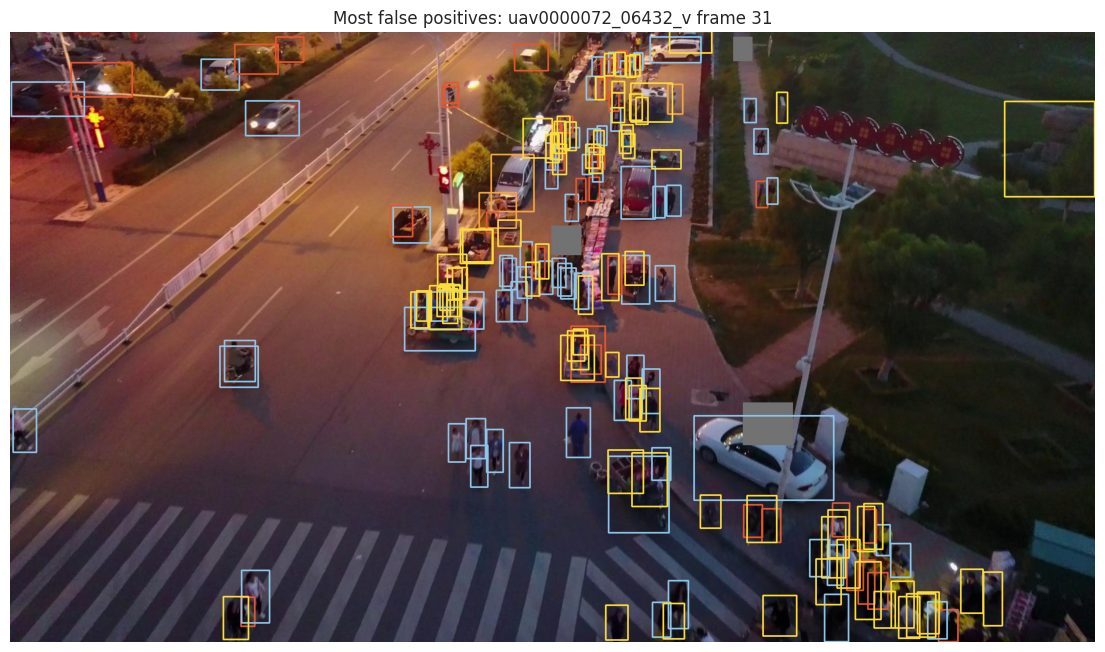

In [64]:
STATUS_COLORS = {"found": (142, 197, 232), "missed": (228, 87, 46), "wrong class": (242, 165, 65)}


def show_frame(image_id, title):
    info_row = img_info.loc[image_id]
    img = cv2.cvtColor(cv2.imread(str(PREP_DIR / info_row["file_name"])), cv2.COLOR_BGR2RGB)
    for r in match[match["image_id"] == image_id].itertuples():
        x, y, w, h = map(int, r.bbox)
        cv2.rectangle(img, (x, y), (x + w, y + h), STATUS_COLORS[r.status], 2)
    for r in false_pos[false_pos["image_id"] == image_id].itertuples():
        x, y, w, h = map(int, r.bbox)
        cv2.rectangle(img, (x, y), (x + w, y + h), (250, 220, 60), 2)
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(img)
    ax.set_title(f"{title}: {info_row['video']} frame {info_row['frame_id']}")
    ax.axis("off")
    plt.show()


per_image = match.groupby("image_id")["status"].value_counts().unstack(fill_value=0).reindex(columns=["found", "wrong class", "missed"], fill_value=0)
per_image["false positives"] = false_pos.groupby("image_id").size().reindex(per_image.index, fill_value=0)
for col in ["missed", "wrong class", "false positives"]:
    show_frame(per_image[col].idxmax(), f"Most {col}")

Failure case 1: A very crowded city intersection, where most of the red boxes are small pedestrians and bikes around the crosswalks and far cars in the upper part of the frame next to the grey ignored regions. This matches the plots above, objects under 16 px and objects at the top of the frame are missed most often, and here the small objects also stand close to each other, so they are easy to lose already in the RPN or to merge with a neighbour.

Failure case 2: A street seen from above, where many vehicles in the far row and several riders are found in the right place but get the wrong class. From this height and at this size the vehicles look very similar, so the model mixes up van and car, which is the most common mistake in the matrix, and riders are confused between motor, bicycle and person in the same way.

Failure case 3: An evening frame with a dense crowd of people and market stalls, where many yellow boxes lie on top of each other on the same groups of people or on things on the stalls, and one big box is on the bushes on the right. In the dim light and with people standing very close together, the model gives several boxes to one group and takes some stall items for people, so here the problem is more the crowd and the darker light than small size.

## Submission

Predictions on the test frames in the competition format: one row per frame, "class score x y width height" for every box,
classes 0–7, x and y are the top-left corner in pixels of the original test frame. Test frames are read directly from the competition data.

In [65]:
@torch.no_grad()
def make_submission(model, path, batch=8):
    model.eval()
    test = pd.read_csv(DATA_DIR / "test_images.csv")
    rows = []
    for start in range(0, len(test), batch):
        part = test.iloc[start:start + batch]
        images = [torch.from_numpy(cv2.cvtColor(cv2.imread(str(DATA_DIR / f)), cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(DEVICE) for f in part["file_name"]]
        with torch.autocast(DEVICE.type, enabled=AMP):
            outputs = model(images)
        for image_id, o in zip(part["image_id"], outputs):
            boxes = o["boxes"].float().cpu().numpy()[:500]
            parts = [f"{l - 1} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}" for (x1, y1, x2, y2), l, s in zip(boxes, o["labels"].tolist()[:500], o["scores"].tolist()[:500])]
            rows.append({"image_id": image_id, "PredictionString": " ".join(parts)})
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

In [66]:
import os, getpass
if not os.environ.get("KAGGLE_API_TOKEN"):
    os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Kaggle token: ")
!pip install -q -U kaggle
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content
!unzip -q -n /content/multiple-object-video-detection-hw-2-ucu-ai-2026.zip "test/*" "test_images.csv" -d /content/data
!ls /content/data

100% 9.88G/9.88G [02:54<00:00, 60.8MB/s]

test  test_images.csv


One submission for the final model (full mode) and one for every experiment in the cv mode. For each of them we used the model that was trained on folds 1–4 and validated on fold 0, so all submissions come from the same split and can be compared with each other.

In [67]:
import gc

SUBMISSIONS = [
    ("more_proposals", "full"),
    ("baseline", "cv"),
    ("more_proposals", "cv"),
    ("giou_loss", "cv"),
]

for name, mode in SUBMISSIONS:
    tag = f"{name}_{mode}_fold0"
    m = build_model(name, MODES[mode]["img_size"])
    m.load_state_dict(torch.load(WORK_DIR / f"{tag}.pt", map_location=DEVICE))
    path = make_submission(m, WORK_DIR / f"submission_{tag}.csv")
    rows = len(pd.read_csv(path))
    print(f"{tag}: {rows} rows → {path}")
    del m
    gc.collect()
    torch.cuda.empty_cache()

more_proposals_full_fold0: 3811 rows → /content/drive/MyDrive/hw2/frcnn/submission_more_proposals_full_fold0.csv
baseline_cv_fold0: 3811 rows → /content/drive/MyDrive/hw2/frcnn/submission_baseline_cv_fold0.csv
more_proposals_cv_fold0: 3811 rows → /content/drive/MyDrive/hw2/frcnn/submission_more_proposals_cv_fold0.csv
giou_loss_cv_fold0: 3811 rows → /content/drive/MyDrive/hw2/frcnn/submission_giou_loss_cv_fold0.csv


## Conclusion

In cross-validation more_proposals gave the best OOF mAP, 0.1811 against 0.1782 for the baseline, but the gain was within the variation between folds, while giou_loss made all metrics worse, so Smooth L1 worked better for us and we chose more_proposals as the final model. The analysis showed that the main weakness of the model is small and far objects, which are lost already in the RPN and even more in the second stage, and most other errors come from classes that look alike from above, like van and car or motor and person.